<a href="https://colab.research.google.com/github/fida-ur-rehman/Sketch2Search/blob/main/sketch2search_evaluating_clip_embeddings_for_sketch_based_image_retrieval.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Sketch2Search: Evaluating CLIP Embeddings for Sketch-Based Image Retrieval

**Student name:** Fida Ur Rehman Khan  
**Student ID:** 1628665  
**Subject:** MAAI901  
**Professor:** Dr. Milan Dordevic  
**Submission date:** 27 Oct 2026  

## Project overview

This notebook compares pretrained CLIP ViT-B/32 with a fine-tuned version for retrieving photographs from hand-drawn sketch queries. Images are compared using cosine similarity, and performance is measured with Recall@1, Recall@5, Recall@10 and Mean Reciprocal Rank (MRR).

**Reproducibility note:** Run the notebook from top to bottom in Google Colab. A GPU runtime is recommended. The archive download and fine-tuning cells may take some time.

## 1. Install and import libraries

The notebook uses Transformers for CLIP, scikit-learn for grouped data splitting and similarity calculations, and Matplotlib for result visualisation.

In [ ]:
%pip -q install "transformers>=4.45,<5" "scikit-learn" "matplotlib" "pandas==2.2.3" "tqdm" "Pillow"

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
diffusers 0.41.0 requires huggingface-hub<2.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.30.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.


In [ ]:
import copy
import os
import re
import random
import tarfile
import urllib.request
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F

from PIL import Image
from tqdm.auto import tqdm
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics.pairwise import cosine_similarity
from torch.utils.data import Dataset, DataLoader
from transformers import CLIPModel, CLIPProcessor

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: Tesla T4


## 2. Download and sample the Sketchy dataset

The archive is downloaded from the Hugging Face repository. To keep the experiment manageable, the archive scan collects up to 20 sketches and 20 photographs per category, with a maximum of 300 images of each type. Because extraction follows archive order, the resulting sample may be biased and should not be treated as representative of the full dataset.

In [ ]:
archive_path = "/content/sketchy_dataset.tar.gz"
archive_url = (
    "https://huggingface.co/datasets/DrRORAL/sketchy-dataset/"
    "resolve/main/dataset/sketchy_dataset_20260309.tar.gz"
)

if not os.path.exists(archive_path) or os.path.getsize(archive_path) < 100_000_000:
    print("Downloading dataset archive. This may take a while...")
    urllib.request.urlretrieve(archive_url, archive_path)

print(f"Archive size: {os.path.getsize(archive_path) / (1024**3):.2f} GB")

Archive size: 1.01 GB


In [ ]:
MAX_PER_CATEGORY = 20
MAX_PER_TYPE = 300
image_data = {"sketch": [], "photo": []}
counts = {"sketch": defaultdict(int), "photo": defaultdict(int)}

with tarfile.open(archive_path, "r|gz") as tar:
    progress = tqdm(desc="Scanning archive")
    while True:
        member = tar.next()
        if member is None:
            break
        progress.update(1)

        if not member.isfile() or not member.name.lower().endswith((".png", ".jpg", ".jpeg")):
            continue

        parts = member.name.split("/")
        if len(parts) < 5:
            continue

        image_type = parts[1]
        category = parts[3]
        if image_type not in image_data:
            continue
        if len(image_data[image_type]) >= MAX_PER_TYPE:
            continue
        if counts[image_type][category] >= MAX_PER_CATEGORY:
            continue

        file_obj = tar.extractfile(member)
        if file_obj is None:
            continue

        try:
            with Image.open(file_obj) as source:
                image = source.convert("RGB")
                image.load()
        except Exception:
            continue

        image_data[image_type].append({
            "image": image,
            "category": category,
            "key": member.name
        })
        counts[image_type][category] += 1

        if all(len(image_data[k]) >= MAX_PER_TYPE for k in image_data):
            break
    progress.close()

print("Sketches:", len(image_data["sketch"]))
print("Photographs:", len(image_data["photo"]))
print("Sketch categories:", len({x["category"] for x in image_data["sketch"]}))
print("Photo categories:", len({x["category"] for x in image_data["photo"]}))

Scanning archive: 0it [00:00, ?it/s]

Sketches: 300
Photographs: 300
Sketch categories: 15
Photo categories: 15


## 3. Inspect the sampled images

This visual check confirms that the archive contains both sketch queries and photographs. The category count and sample size should be recorded when describing the dataset in the report.

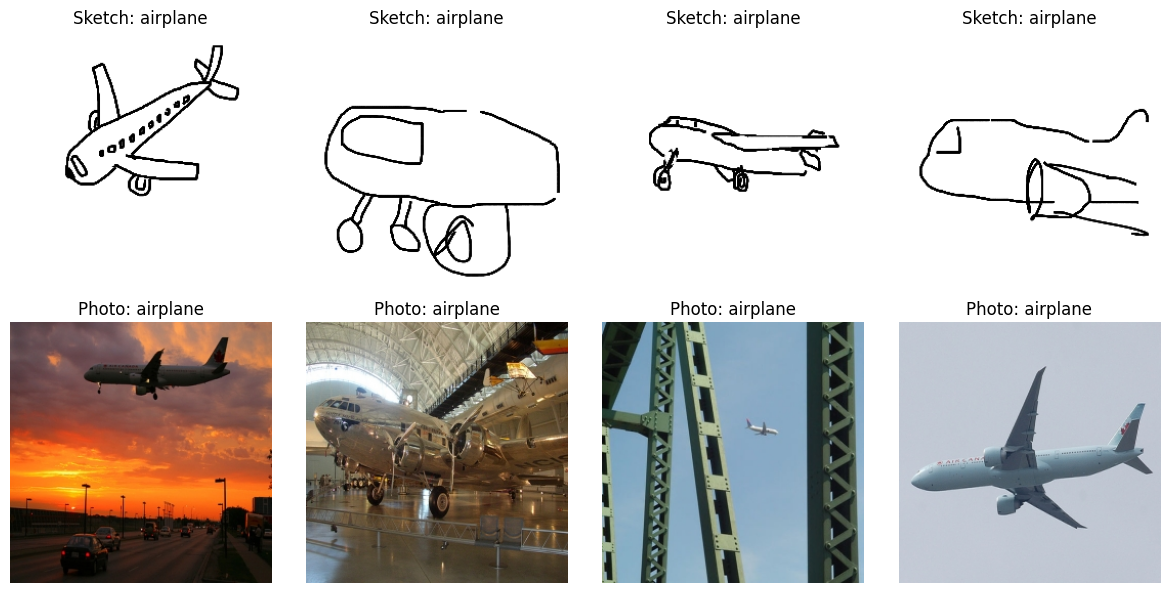

In [ ]:
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for col, item in enumerate(image_data["sketch"][:4]):
    axes[0, col].imshow(item["image"])
    axes[0, col].set_title(f"Sketch: {item['category']}")
    axes[0, col].axis("off")

for col, item in enumerate(image_data["photo"][:4]):
    axes[1, col].imshow(item["image"])
    axes[1, col].set_title(f"Photo: {item['category']}")
    axes[1, col].axis("off")

plt.tight_layout()
plt.show()

## 4. Match sketches to photographs and create object-disjoint splits

The filename is used to identify the underlying object. Sketches and photographs with the same object identifier are paired. GroupShuffleSplit then keeps each object in only one of the training, validation or test sets, reducing object-level leakage.

In [ ]:
def get_object_id(path):
    filename = os.path.basename(path)
    filename = re.sub(r"-\d+(?=\.[^.]+$)", "", filename)
    return os.path.splitext(filename)[0]

photos_by_id = defaultdict(list)
for photo in image_data["photo"]:
    photos_by_id[get_object_id(photo["key"])].append(photo)

matched_pairs = []
for sketch in image_data["sketch"]:
    object_id = get_object_id(sketch["key"])
    for photo in photos_by_id.get(object_id, []):
        matched_pairs.append({
            "sketch": sketch,
            "photo": photo,
            "object_id": object_id,
            "category": sketch["category"]
        })

print("Matched pairs:", len(matched_pairs))
if not matched_pairs:
    raise ValueError("No sketch-photo pairs were found. Check the archive folder structure and filenames.")

Matched pairs: 300


In [ ]:
groups = np.array([pair["object_id"] for pair in matched_pairs])
indices = np.arange(len(matched_pairs))

splitter_test = GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=SEED)
trainval_idx, test_idx = next(splitter_test.split(indices, groups=groups))

splitter_val = GroupShuffleSplit(n_splits=1, test_size=0.1765, random_state=SEED)
train_rel, val_rel = next(
    splitter_val.split(trainval_idx, groups=groups[trainval_idx])
)

train_idx = trainval_idx[train_rel]
val_idx = trainval_idx[val_rel]

train_pairs = [matched_pairs[i] for i in train_idx]
val_idx = trainval_idx[val_rel]
val_pairs = [matched_pairs[i] for i in val_idx]
test_pairs = [matched_pairs[i] for i in test_idx]

train_ids = {p["object_id"] for p in train_pairs}
val_ids = {p["object_id"] for p in val_pairs}
test_ids = {p["object_id"] for p in test_pairs}

split_summary = pd.DataFrame([
    {"Split": "Training", "Pairs": len(train_pairs), "Unique objects": len(train_ids)},
    {"Split": "Validation", "Pairs": len(val_pairs), "Unique objects": len(val_ids)},
    {"Split": "Test", "Pairs": len(test_pairs), "Unique objects": len(test_ids)}
])
display(split_summary)

print("Object overlap (train/validation):", len(train_ids & val_ids))
print("Object overlap (train/test):", len(train_ids & test_ids))
print("Object overlap (validation/test):", len(val_ids & test_ids))
assert not (train_ids & val_ids or train_ids & test_ids or val_ids & test_ids)

,Split,Pairs,Unique objects
0,Training,209,37
1,Validation,41,8
2,Test,50,9


Object overlap (train/validation): 0
Object overlap (train/test): 0
Object overlap (validation/test): 0


## 5. Load pretrained CLIP

The pretrained CLIP ViT-B/32 model provides the baseline. Its processor applies the input transformations expected by the model. A separate copy is preserved so that the baseline remains unchanged during fine-tuning.

In [ ]:
model_name = "openai/clip-vit-base-patch32"
processor = CLIPProcessor.from_pretrained(model_name)
model = CLIPModel.from_pretrained(model_name).to(device)
baseline_model = copy.deepcopy(model).to(device).eval()

total_params = sum(parameter.numel() for parameter in model.parameters())
print("Model:", model_name)
print(f"Total parameters: {total_params:,}")

Using a slow image processor as `use_fast` is unset and a slow processor was saved with this model. `use_fast=True` will be the default behavior in v4.52, even if the model was saved with a slow processor. This will result in minor differences in outputs. You'll still be able to use a slow processor with `use_fast=False`.
/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/592 [00:00<?, ?B/s]

config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

pytorch_model.bin:   0%|          | 0.00/605M [00:00<?, ?B/s]

Model: openai/clip-vit-base-patch32
Total parameters: 151,277,313


## 6. Prepare the training data and contrastive loss

The multi-positive loss treats examples with the same object identifier as positive matches. This is useful when an object has more than one associated sketch, since multiple sketches may correctly match the same photograph.

In [ ]:
class SketchPhotoDataset(Dataset):
    def __init__(self, pairs):
        self.pairs = pairs

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, index):
        pair = self.pairs[index]
        sketch = processor(images=pair["sketch"]["image"], return_tensors="pt")["pixel_values"].squeeze(0)
        photo = processor(images=pair["photo"]["image"], return_tensors="pt")["pixel_values"].squeeze(0)
        return {"sketch": sketch, "photo": photo, "object_id": pair["object_id"]}


def multi_positive_clip_loss(sketch_features, photo_features, object_ids, temperature=0.07):
    sketch_features = F.normalize(sketch_features.float(), dim=-1)
    photo_features = F.normalize(photo_features.float(), dim=-1)

    object_ids = list(object_ids)
    id_to_label = {object_id: index for index, object_id in enumerate(set(object_ids))}
    labels = torch.tensor(
        [id_to_label[object_id] for object_id in object_ids],
        device=sketch_features.device
    )

    logits = sketch_features @ photo_features.T / temperature
    positive_mask = (labels[:, None] == labels[None, :]).float()

    sketch_log_probs = F.log_softmax(logits, dim=1)
    sketch_loss = -(positive_mask * sketch_log_probs).sum(dim=1) / positive_mask.sum(dim=1)

    photo_log_probs = F.log_softmax(logits.T, dim=1)
    photo_loss = -(positive_mask.T * photo_log_probs).sum(dim=1) / positive_mask.T.sum(dim=1)

    return (sketch_loss.mean() + photo_loss.mean()) / 2


train_dataset = SketchPhotoDataset(train_pairs)
val_dataset = SketchPhotoDataset(val_pairs)

train_loader = DataLoader(train_dataset, batch_size=8, shuffle=True, num_workers=0)
val_loader = DataLoader(val_dataset, batch_size=8, shuffle=False, num_workers=0)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))

Training batches: 27
Validation batches: 6


## 7. Fine-tune CLIP

All model parameters are trainable. The experiment uses AdamW for five epochs. Validation loss is calculated after each epoch, and the checkpoint with the lowest validation loss is restored for evaluation.

In [ ]:
EPOCHS = 5
LEARNING_RATE = 1e-6
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=0.01)


def batch_loss(batch):
    sketches = batch["sketch"].to(device)
    photos = batch["photo"].to(device)

    with torch.autocast(
        device_type="cuda",
        dtype=torch.float16,
        enabled=(device.type == "cuda")
    ):
        sketch_features = model.get_image_features(pixel_values=sketches)
        photo_features = model.get_image_features(pixel_values=photos)

    if not isinstance(sketch_features, torch.Tensor):
        sketch_features = sketch_features.pooler_output
    if not isinstance(photo_features, torch.Tensor):
        photo_features = photo_features.pooler_output

    return multi_positive_clip_loss(
        sketch_features, photo_features, batch["object_id"]
    )


best_val_loss = float("inf")
best_model_state = copy.deepcopy(model.state_dict())
training_history = []

for epoch in range(EPOCHS):
    model.train()
    train_losses = []

    for batch in train_loader:
        optimizer.zero_grad(set_to_none=True)
        loss = batch_loss(batch)
        if not torch.isfinite(loss):
            raise RuntimeError("Training loss became non-finite.")
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        train_losses.append(loss.item())

    model.eval()
    val_losses = []
    with torch.no_grad():
        for batch in val_loader:
            val_loss = batch_loss(batch)
            if not torch.isfinite(val_loss):
                raise RuntimeError("Validation loss became non-finite.")
            val_losses.append(val_loss.item())

    mean_train_loss = float(np.mean(train_losses))
    mean_val_loss = float(np.mean(val_losses))
    training_history.append({
        "epoch": epoch + 1,
        "train_loss": mean_train_loss,
        "val_loss": mean_val_loss
    })

    print(
        f"Epoch {epoch + 1}/{EPOCHS} | "
        f"Train loss: {mean_train_loss:.4f} | "
        f"Validation loss: {mean_val_loss:.4f}"
    )

    if mean_val_loss < best_val_loss:
        best_val_loss = mean_val_loss
        best_model_state = copy.deepcopy(model.state_dict())

model.load_state_dict(best_model_state)
model.eval()
print(f"Best validation loss: {best_val_loss:.4f}")

model.safetensors:   0%|          | 0.00/605M [00:00<?, ?B/s]

Epoch 1/5 | Train loss: 1.0464 | Validation loss: 1.3993
Epoch 2/5 | Train loss: 0.5219 | Validation loss: 1.4050
Epoch 3/5 | Train loss: 0.3057 | Validation loss: 1.4388
Epoch 4/5 | Train loss: 0.2642 | Validation loss: 1.4927
Epoch 5/5 | Train loss: 0.2144 | Validation loss: 1.5325
Best validation loss: 1.3993


## 8. Build the strict retrieval gallery

The gallery excludes photographs belonging to training and validation objects. This keeps the retrieval gallery object-disjoint from the data used for model adaptation and checkpoint selection.

In [ ]:
train_val_ids = train_ids | val_ids
strict_gallery = [
    photo for photo in image_data["photo"]
    if get_object_id(photo["key"]) not in train_val_ids
]

test_sketches = [pair["sketch"] for pair in test_pairs]
test_object_ids = [pair["object_id"] for pair in test_pairs]
gallery_ids = [get_object_id(photo["key"]) for photo in strict_gallery]

print("Test sketches:", len(test_sketches))
print("Unique test objects:", len(set(test_object_ids)))
print("Strict gallery photos:", len(strict_gallery))
print("Unique gallery objects:", len(set(gallery_ids)))
print("Test objects missing from gallery:", len(set(test_object_ids) - set(gallery_ids)))
print("Train/validation objects in gallery:", len(train_val_ids & set(gallery_ids)))

assert len(set(test_object_ids) - set(gallery_ids)) == 0
assert len(gallery_ids) == len(set(gallery_ids))
assert len(train_val_ids & set(gallery_ids)) == 0

Test sketches: 50
Unique test objects: 9
Strict gallery photos: 255
Unique gallery objects: 255
Test objects missing from gallery: 0
Train/validation objects in gallery: 0


## 9. Extract embeddings and evaluate retrieval

Each sketch and gallery photograph is converted into a normalised CLIP embedding. The gallery is ranked by cosine similarity. Metrics are calculated for each sketch, averaged within each underlying object, and then averaged across objects so that each test object has equal weight.

In [ ]:
def extract_embeddings(items, model, batch_size=16):
    model.eval()
    embeddings = []

    with torch.no_grad():
        for start in range(0, len(items), batch_size):
            batch_items = items[start:start + batch_size]
            pixels = processor(
                images=[item["image"] for item in batch_items],
                return_tensors="pt"
            )["pixel_values"].to(device)

            features = model.get_image_features(pixel_values=pixels)
            if not isinstance(features, torch.Tensor):
                features = features.pooler_output

            embeddings.append(F.normalize(features.float(), dim=-1).cpu().numpy())

    return np.vstack(embeddings)


def evaluate_object_level(model, model_name, gallery):
    current_gallery_ids = [get_object_id(photo["key"]) for photo in gallery]
    sketch_features = extract_embeddings(test_sketches, model)
    photo_features = extract_embeddings(gallery, model)
    similarities = cosine_similarity(sketch_features, photo_features)

    per_object = defaultdict(list)
    for index, target_id in enumerate(test_object_ids):
        ranking = np.argsort(similarities[index])[::-1]
        relevant = [rank + 1 for rank, photo_index in enumerate(ranking)
                    if current_gallery_ids[photo_index] == target_id]

        first_rank = relevant[0] if relevant else None
        per_object[target_id].append({
            "Recall@1": float(first_rank is not None and first_rank <= 1),
            "Recall@5": float(first_rank is not None and first_rank <= 5),
            "Recall@10": float(first_rank is not None and first_rank <= 10),
            "MRR": 1.0 / first_rank if first_rank is not None else 0.0
        })

    object_scores = []
    for object_id, sketch_scores in per_object.items():
        object_scores.append({
            metric: np.mean([scores[metric] for scores in sketch_scores])
            for metric in ["Recall@1", "Recall@5", "Recall@10", "MRR"]
        })

    object_df = pd.DataFrame(object_scores)
    return {
        "Model": model_name,
        "Test objects": len(object_df),
        **{metric: object_df[metric].mean()
           for metric in ["Recall@1", "Recall@5", "Recall@10", "MRR"]}
    }


object_level_results = pd.DataFrame([
    evaluate_object_level(baseline_model, "Pretrained CLIP", strict_gallery),
    evaluate_object_level(model, "Fine-tuned CLIP", strict_gallery)
])
display(object_level_results.round(4))

,Model,Test objects,Recall@1,Recall@5,Recall@10,MRR
0,Pretrained CLIP,9,0.0111,0.1778,0.3370,0.1261
1,Fine-tuned CLIP,9,0.0185,0.2407,0.4873,0.1710


## 10. Audit the evaluation setup

These checks confirm that the gallery contains unique objects, all test objects are represented, and training/validation objects are excluded. They do not, by themselves, establish that the model generalises beyond this small sample.

In [ ]:
test_id_set = set(test_object_ids)
gallery_id_set = set(gallery_ids)

audit = {
    "Test sketches": len(test_sketches),
    "Unique test objects": len(test_id_set),
    "Gallery photographs": len(strict_gallery),
    "Unique gallery objects": len(gallery_id_set),
    "Test objects missing from gallery": len(test_id_set - gallery_id_set),
    "Duplicate gallery IDs": len(gallery_ids) - len(gallery_id_set),
    "Training/validation objects in gallery": len(train_val_ids & gallery_id_set)
}
display(pd.DataFrame(audit.items(), columns=["Check", "Result"]))

,Check,Result
0,Test sketches,50
1,Unique test objects,9
2,Gallery photographs,255
3,Unique gallery objects,255
4,Test objects missing from gallery,0
5,Duplicate gallery IDs,0
6,Training/validation objects in gallery,0


## 11. Visualise training and retrieval results

The first plot shows training and validation loss. The second compares the two models using the four retrieval metrics. The third displays qualitative examples from both models; the labels indicate whether a retrieved photograph matches the query's object identifier.

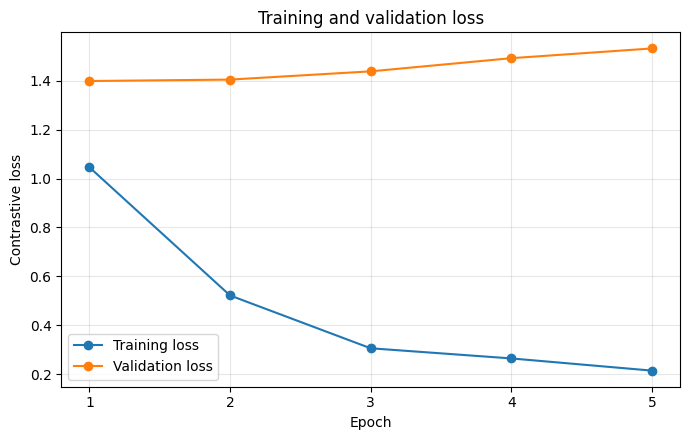

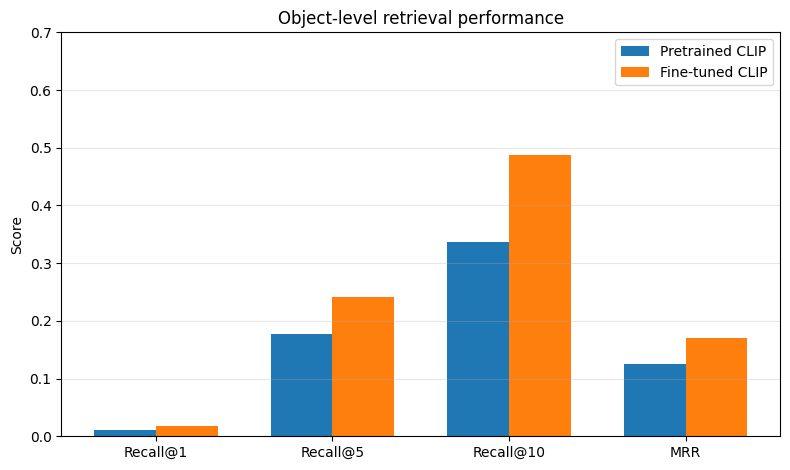

In [ ]:
history = pd.DataFrame(training_history)

plt.figure(figsize=(7, 4.5))
plt.plot(history["epoch"], history["train_loss"], marker="o", label="Training loss")
plt.plot(history["epoch"], history["val_loss"], marker="o", label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Contrastive loss")
plt.title("Training and validation loss")
plt.xticks(history["epoch"])
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("/content/figure1_training_validation_loss.png", dpi=300, bbox_inches="tight")
plt.show()

metrics = ["Recall@1", "Recall@5", "Recall@10", "MRR"]
x = np.arange(len(metrics))
width = 0.35
baseline_scores = object_level_results.iloc[0][metrics].astype(float).values
finetuned_scores = object_level_results.iloc[1][metrics].astype(float).values

plt.figure(figsize=(8, 4.8))
plt.bar(x - width / 2, baseline_scores, width, label="Pretrained CLIP")
plt.bar(x + width / 2, finetuned_scores, width, label="Fine-tuned CLIP")
plt.xticks(x, metrics)
plt.ylabel("Score")
plt.ylim(0, 0.7)
plt.title("Object-level retrieval performance")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig("/content/figure2_retrieval_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

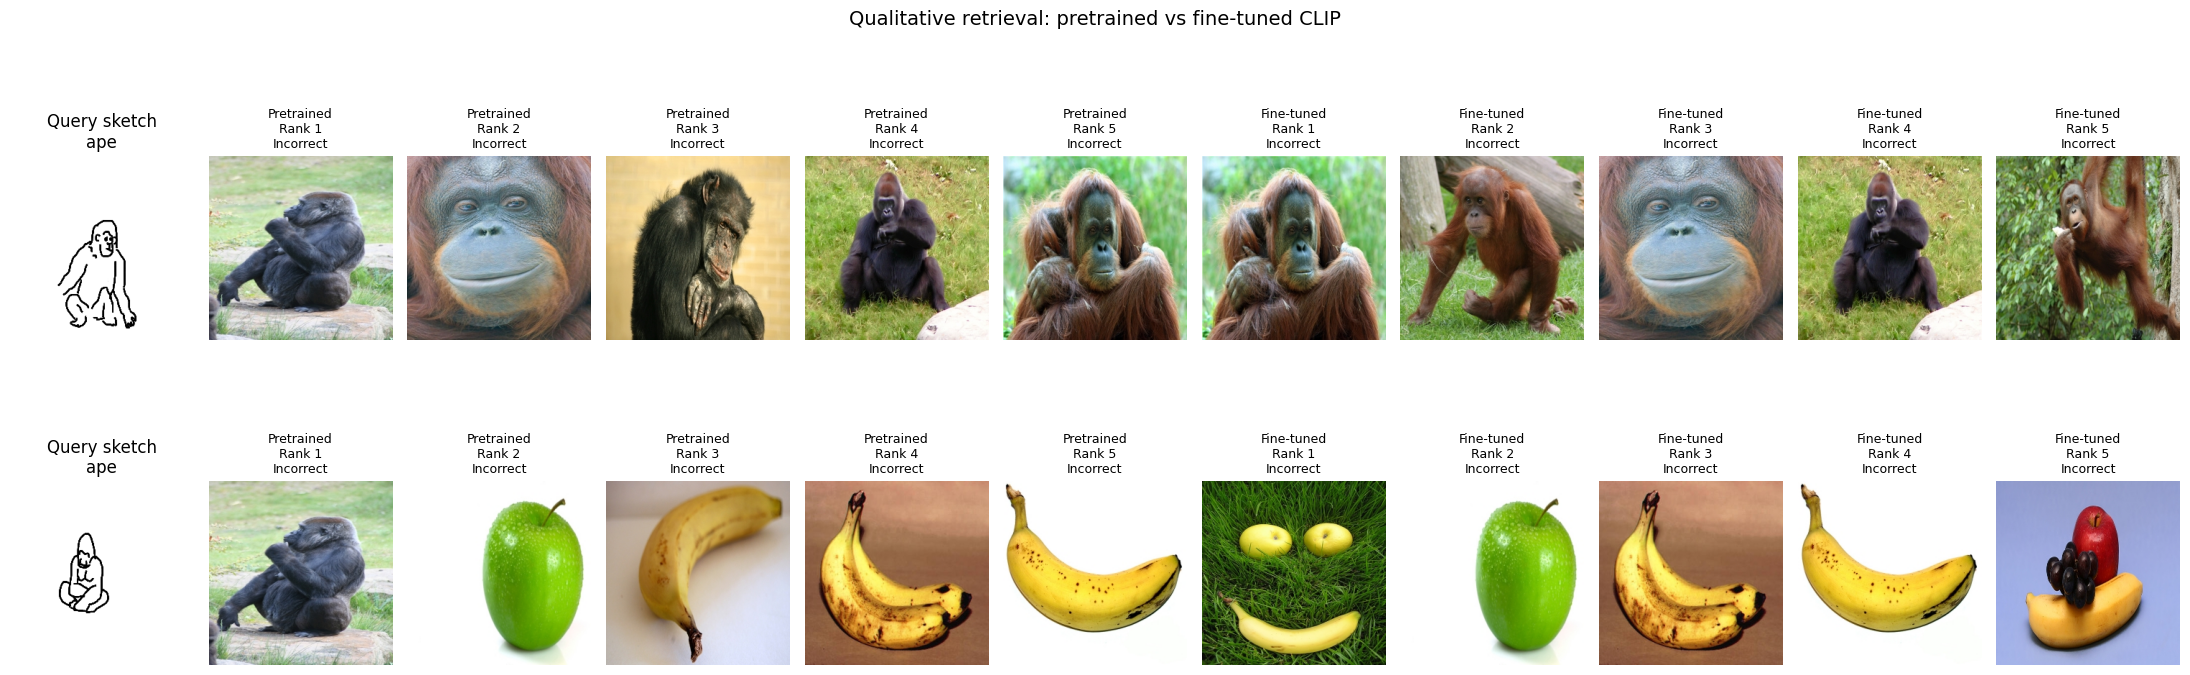

In [ ]:
selected_indices = [6, 0]
selected_pairs = [test_pairs[index] for index in selected_indices]
selected_sketches = [pair["sketch"] for pair in selected_pairs]

baseline_query = extract_embeddings(selected_sketches, baseline_model)
baseline_gallery = extract_embeddings(strict_gallery, baseline_model)
tuned_query = extract_embeddings(selected_sketches, model)
tuned_gallery = extract_embeddings(strict_gallery, model)

baseline_similarity = cosine_similarity(baseline_query, baseline_gallery)
tuned_similarity = cosine_similarity(tuned_query, tuned_gallery)

fig, axes = plt.subplots(2, 11, figsize=(22, 8), squeeze=False)

for row, pair in enumerate(selected_pairs):
    axes[row, 0].imshow(pair["sketch"]["image"])
    axes[row, 0].set_title(f"Query sketch\n{pair['category']}")
    axes[row, 0].axis("off")

    for start_col, scores, label in [
        (1, baseline_similarity, "Pretrained"),
        (6, tuned_similarity, "Fine-tuned")
    ]:
        ranking = np.argsort(scores[row])[::-1][:5]
        for rank, photo_index in enumerate(ranking):
            col = start_col + rank
            photo = strict_gallery[photo_index]
            is_match = get_object_id(photo["key"]) == pair["object_id"]
            axes[row, col].imshow(photo["image"])
            axes[row, col].set_title(
                f"{label}\nRank {rank + 1}\n{'Match' if is_match else 'Incorrect'}",
                fontsize=9
            )
            axes[row, col].axis("off")

fig.suptitle("Qualitative retrieval: pretrained vs fine-tuned CLIP", fontsize=14)
plt.tight_layout()
plt.savefig("/content/figure3_qualitative_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

## 12. Save results and submission figures

The following files are saved in the Colab session. Download them before closing the runtime if they are needed for the report.

In [ ]:
object_level_results.to_csv("/content/sketch2search_results.csv", index=False)

print("Saved files:")
for filename in [
    "/content/sketch2search_results.csv",
    "/content/figure1_training_validation_loss.png",
    "/content/figure2_retrieval_comparison.png",
    "/content/figure3_qualitative_comparison.png"
]:
    print(filename, "| exists:", os.path.exists(filename))

print("\nFinal experiment summary")
print("Model:", model_name)
print("Training pairs:", len(train_pairs))
print("Validation pairs:", len(val_pairs))
print("Test pairs:", len(test_pairs))
print("Unique test objects:", len(set(test_object_ids)))
print("Strict gallery photos:", len(strict_gallery))
print("Best validation loss:", round(best_val_loss, 4))
display(object_level_results.round(4))

Saved files:
/content/sketch2search_results.csv | exists: True
/content/figure1_training_validation_loss.png | exists: True
/content/figure2_retrieval_comparison.png | exists: True
/content/figure3_qualitative_comparison.png | exists: True

Final experiment summary
Model: openai/clip-vit-base-patch32
Training pairs: 209
Validation pairs: 41
Test pairs: 50
Unique test objects: 9
Strict gallery photos: 255
Best validation loss: 1.3993


,Model,Test objects,Recall@1,Recall@5,Recall@10,MRR
0,Pretrained CLIP,9,0.0111,0.1778,0.3370,0.1261
1,Fine-tuned CLIP,9,0.0185,0.2407,0.4873,0.1710
